<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Ejercicios/Soluciones/07_Taller_CNN_Texto_Solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Taller práctico: redes convolucionales para texto (solución)</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Instrucciones</h2>

Solución de referencia del taller [`07_Taller_CNN_Texto.ipynb`](../07_Taller_CNN_Texto.ipynb).

Hay muchas soluciones válidas: esta es una de ellas. Compara tus resultados y, sobre todo, tus conclusiones.

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Ejercicio 1. Convoluciones 1D</span>](#ejercicio-1)
- [<span style="color: #005C99;">Ejercicio 2. Clasificación con CNN</span>](#ejercicio-2)
- [<span style="color: #005C99;">Ejercicio 3. Filtros de varios tamaños</span>](#ejercicio-3)
- [<span style="color: #005C99;">Ejercicio 4. Comparación CNN vs LSTM</span>](#ejercicio-4)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib seaborn scikit-learn tensorflow datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # oculta mensajes informativos de TensorFlow

import re
import string
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)  # fija las semillas de Python, NumPy y TensorFlow

import seaborn as sns
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

idiomas = load_dataset("papluca/language-identification")
df_train, df_val, df_test = (idiomas[s].to_pandas() for s in ["train", "validation", "test"])
CLASES = sorted(df_train.labels.unique())
c2i = {c: i for i, c in enumerate(CLASES)}
X_train_txt, X_val_txt, X_test_txt = df_train.text.tolist(), df_val.text.tolist(), df_test.text.tolist()
y_train, y_val, y_test = (df.labels.map(c2i).to_numpy() for df in (df_train, df_val, df_test))
print(f"Entrenamiento: {len(X_train_txt)} | Validación: {len(X_val_txt)} | Prueba: {len(X_test_txt)}")
print("Idiomas:", CLASES)

Entrenamiento: 70000 | Validación: 10000 | Prueba: 10000
Idiomas: ['ar', 'bg', 'de', 'el', 'en', 'es', 'fr', 'hi', 'it', 'ja', 'nl', 'pl', 'pt', 'ru', 'sw', 'th', 'tr', 'ur', 'vi', 'zh']


---

<a id="ejercicio-1"></a>
<h2 style="color: #007ACC;">Ejercicio 1. Convoluciones 1D</h2>

**Objetivo:** generalizar la convolución 1D del cuaderno 15 con *stride*, dilatación y relleno, y medir empíricamente el campo receptivo de una red apilada.

1. Implementa en NumPy `conv1d(X, W, b, stride=1, dilatacion=1, relleno="valid")`, con `X` de forma `(T, d)`, `W` de forma `(k, d, m)` y `b` de forma `(m,)`, **sin** función de activación. Con `relleno="same"` y `stride=1`, la salida debe tener longitud $T$: rellena con ceros $\lfloor p/2 \rfloor$ posiciones a la izquierda y el resto a la derecha, donde $p = d_{\text{il}}(k - 1)$ es el relleno total.
2. Comprueba que coincide con `layers.Conv1D` (con `activation=None`) en al menos estas cuatro configuraciones: `k=3` básica; `k=3, strides=2`; `k=3, dilation_rate=2`; `k=4, padding="same"`. Verifica también la fórmula de la longitud de salida con relleno `valid`: $L = \lfloor (T - d_{\text{il}}(k-1) - 1)/s \rfloor + 1$.
3. El campo receptivo de $L$ capas con anchos $k_\ell$, dilataciones $d_\ell$ y *strides* $s_\ell$ es $r = 1 + \sum_\ell (k_\ell - 1)\, d_\ell \prod_{i<\ell} s_i$. Calcúlalo para una red de tres `Conv1D` con `k=3` y `strides=2` en cada capa.
4. Mide el campo receptivo **empíricamente** para esa red (con pesos aleatorios): calcula la salida para una entrada aleatoria, modifica solo la posición 40 de la entrada y cuenta qué posiciones de la salida cambian. Luego haz lo contrario: para la salida en la posición 5, encuentra qué posiciones de la entrada la afectan. ¿Coincide con la fórmula?

In [3]:
def conv1d(X, W, b, stride=1, dilatacion=1, relleno="valid"):
    k = W.shape[0]
    alcance = dilatacion * (k - 1)  # distancia entre la primera y la última posición del filtro
    if relleno == "same":
        X = np.pad(X, ((alcance // 2, alcance - alcance // 2), (0, 0)))
    T = X.shape[0]
    salidas = []
    for t in range(0, T - alcance, stride):
        ventana = X[t:t + alcance + 1:dilatacion]  # k posiciones separadas por la dilatación
        salidas.append(np.einsum("kd,kdm->m", ventana, W) + b)
    return np.array(salidas)


rng = np.random.default_rng(SEED)
T, d, m = 20, 6, 4
X = rng.normal(size=(T, d)).astype("float32")
configuraciones = [dict(kernel_size=3), dict(kernel_size=3, strides=2), dict(kernel_size=3, dilation_rate=2),
                   dict(kernel_size=4, padding="same"), dict(kernel_size=5, strides=3)]
filas = []
for cfg in configuraciones:
    capa = layers.Conv1D(m, **cfg)
    salida_keras = capa(X[None])[0].numpy()
    W, b = capa.get_weights()
    k, s, dil = cfg["kernel_size"], cfg.get("strides", 1), cfg.get("dilation_rate", 1)
    salida = conv1d(X, W, b, s, dil, cfg.get("padding", "valid"))
    formula = (T - dil * (k - 1) - 1) // s + 1 if cfg.get("padding", "valid") == "valid" else T
    filas.append({"configuración": str(cfg), "longitud Keras": salida_keras.shape[0],
                  "longitud fórmula": formula, "¿coinciden?": np.allclose(salida, salida_keras, atol=1e-5)})
pd.DataFrame(filas)

,configuración,longitud Keras,longitud fórmula,¿coinciden?
0,{'kernel_size': 3},18,18,True
1,"{'kernel_size': 3, 'strides': 2}",9,9,True
2,"{'kernel_size': 3, 'dilation_rate': 2}",16,16,True
3,"{'kernel_size': 4, 'padding': 'same'}",20,20,True
4,"{'kernel_size': 5, 'strides': 3}",6,6,True


In [4]:
def campo_receptivo(anchos, dilataciones, strides):
    r, salto = 1, 1
    for k, dil, s in zip(anchos, dilataciones, strides):
        r += (k - 1) * dil * salto
        salto *= s
    return r


print("Campo receptivo según la fórmula:", campo_receptivo([3, 3, 3], [1, 1, 1], [2, 2, 2]))

keras.utils.set_random_seed(SEED)
red = keras.Sequential([keras.Input(shape=(80, 1))] + [layers.Conv1D(1, 3, strides=2) for _ in range(3)])
x = rng.normal(size=(1, 80, 1)).astype("float32")
base = red(x).numpy()[0, :, 0]

x_mod = x.copy()
x_mod[0, 40, 0] += 10
cambian = np.where(np.abs(red(x_mod).numpy()[0, :, 0] - base) > 1e-6)[0]
print(f"Longitud de la salida: {len(base)} | al modificar la entrada 40 cambian las salidas: {cambian.tolist()}")

afectan = []
for p in range(80):
    x_mod = x.copy()
    x_mod[0, p, 0] += 10
    if abs(red(x_mod).numpy()[0, 5, 0] - base[5]) > 1e-6:
        afectan.append(p)
print(f"La salida 5 depende de las entradas {afectan[0]}–{afectan[-1]}: {len(afectan)} posiciones")

Campo receptivo según la fórmula: 15
Longitud de la salida: 9 | al modificar la entrada 40 cambian las salidas: [4, 5]


La salida 5 depende de las entradas 40–54: 15 posiciones


**Interpretación:** la implementación coincide con Keras en todas las configuraciones, y la fórmula de la longitud de salida también. Con tres capas de `k=3` y `strides=2`, la fórmula da un campo receptivo de $1 + 2 + 4 + 8 = 15$ posiciones, y el experimento lo confirma: la salida 5 depende exactamente de 15 entradas consecutivas. Al mismo tiempo, la salida (9 posiciones) es casi 9 veces más corta que la entrada (80). El *stride*, como la dilatación, hace crecer el campo receptivo de forma **exponencial** con la profundidad, pero a costa de resolución: cada salida resume un bloque de entradas y la red pierde la posición exacta de cada patrón. Para clasificar un texto completo eso no importa; para etiquetar cada carácter o palabra (NER) sí.

---

<a id="ejercicio-2"></a>
<h2 style="color: #007ACC;">Ejercicio 2. Clasificación con CNN</h2>

**Objetivo:** entrenar una CNN de caracteres para identificar el idioma y compararla con una línea base de N-gramas de caracteres.

1. Explora los datos: ¿cuántos ejemplos hay por idioma? ¿Cuál es la distribución de la longitud en **caracteres**? Elige `LONGITUD` como el percentil 95 de la longitud en entrenamiento.
2. **Línea base:** entrena un `TfidfVectorizer` de N-gramas de **caracteres** (`analyzer="char_wb"`, `ngram_range=(1, 3)`, como máximo 100 000 rasgos) con una regresión logística. Reporta la exactitud en validación.
3. Crea una capa `TextVectorization` a nivel de caracteres (`split="character"`, `standardize="lower"`) con un vocabulario de como máximo 2 000 caracteres y `output_sequence_length=LONGITUD`. ¿Cuántos caracteres distintos hay en entrenamiento? ¿Por qué hay tantos?
4. Entrena una CNN de caracteres: `Embedding` de dimensión 32, `Conv1D` de 128 filtros de ancho 5 con ReLU, `GlobalMaxPooling1D`, `Dropout(0.3)` y una capa de salida softmax de 20 clases. Usa parada temprana con paciencia 2 y como máximo 15 épocas. Reporta la exactitud en validación y el tiempo de entrenamiento.
5. ¿Qué pares de idiomas se confunden más? Muestra los 5 pares más frecuentes en la matriz de confusión de validación y algunos ejemplos mal clasificados.

In [5]:
print(df_train.labels.value_counts().describe()[["min", "max"]].to_dict())
largos = df_train.text.str.len()
print(largos.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(0).to_dict())
LONGITUD = int(largos.quantile(0.95))
print(f"LONGITUD = {LONGITUD} caracteres ({(largos > LONGITUD).mean():.1%} de los textos se recortan)")

{'min': 3500.0, 'max': 3500.0}
{'count': 70000.0, 'mean': 111.0, 'std': 103.0, 'min': 2.0, '50%': 82.0, '90%': 219.0, '95%': 281.0, '99%': 491.0, 'max': 2422.0}
LONGITUD = 281 caracteres (5.0% de los textos se recortan)


In [6]:
inicio = time.perf_counter()
tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3), max_features=100_000, sublinear_tf=True)
T_train, T_val = tfidf.fit_transform(X_train_txt), tfidf.transform(X_val_txt)
base = LogisticRegression(max_iter=1000, C=10).fit(T_train, y_train)
t_base = time.perf_counter() - inicio
inicio = time.perf_counter()
acc_base = accuracy_score(y_val, base.predict(tfidf.transform(X_val_txt)))
t_inf_base = time.perf_counter() - inicio
print(f"TF-IDF de caracteres + regresión logística: exactitud en validación {acc_base:.4f} "
      f"(entrenamiento {t_base:.0f} s)")

TF-IDF de caracteres + regresión logística: exactitud en validación 0.9945 (entrenamiento 24 s)


In [7]:
vec = layers.TextVectorization(max_tokens=2000, split="character", standardize="lower",
                               output_sequence_length=LONGITUD)
vec.adapt(X_train_txt)
distintos = len({c for t in X_train_txt for c in t.lower()})
print(f"Caracteres distintos en entrenamiento: {distintos} | vocabulario usado: {vec.vocabulary_size()}")
X_train, X_val, X_test = (vec(np.array(t)).numpy() for t in (X_train_txt, X_val_txt, X_test_txt))
V = vec.vocabulary_size()


def entrenar(modelo, nombre, epocas=15):
    modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    inicio = time.perf_counter()
    h = modelo.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epocas, batch_size=256, verbose=0,
                   callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)])
    t = time.perf_counter() - inicio
    inicio = time.perf_counter()
    modelo.predict(X_val, batch_size=512, verbose=0)
    return {"modelo": nombre, "parámetros": modelo.count_params(), "épocas": len(h.history["loss"]),
            "tiempo por época (s)": t / len(h.history["loss"]),
            "inferencia en validación (s)": time.perf_counter() - inicio,
            "exactitud en validación": modelo.evaluate(X_val, y_val, verbose=0)[1]}


keras.utils.set_random_seed(SEED)
cnn = keras.Sequential([
    keras.Input(shape=(LONGITUD,), dtype="int64"),
    layers.Embedding(V, 32),
    layers.Conv1D(128, 5, activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(len(CLASES), activation="softmax"),
])
resultados = [{"modelo": "TF-IDF caracteres + RL", "inferencia en validación (s)": t_inf_base,
               "exactitud en validación": acc_base},
              entrenar(cnn, "CNN de caracteres (k = 5)")]
pd.DataFrame(resultados).set_index("modelo").round(4)

Caracteres distintos en entrenamiento: 4257 | vocabulario usado: 2000


,inferencia en validación (s),exactitud en validación,parámetros,épocas,tiempo por época (s)
modelo,,,,,
TF-IDF caracteres + RL,0.5894,0.9945,NaN,NaN,NaN
CNN de caracteres (k = 5),0.1602,0.9774,87188.0,4.0,3.5747


In [8]:
pred_val = cnn.predict(X_val, batch_size=512, verbose=0).argmax(1)
cm = confusion_matrix(y_val, pred_val)
np.fill_diagonal(cm, 0)
pares = sorted(((cm[i, j], CLASES[i], CLASES[j]) for i in range(len(CLASES)) for j in range(len(CLASES)) if cm[i, j]),
               reverse=True)[:5]
print("Pares más confundidos (real → predicho):", [(f"{a}→{b}", n) for n, a, b in pares])

filas = []
for _, a, b in pares:
    idx = np.where((y_val == c2i[a]) & (pred_val == c2i[b]))[0][:2]
    filas += [{"real → predicho": f"{a} → {b}", "texto": X_val_txt[i]} for i in idx]
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(filas)

Pares más confundidos (real → predicho): [('bg→ru', np.int64(43)), ('hi→sw', np.int64(18)), ('de→nl', np.int64(17)), ('ru→bg', np.int64(15)), ('ur→sw', np.int64(14))]


,real → predicho,texto
0,bg → ru,"Ще се върнете на него веднага и ще вземете екипажа си с вас, иначе... Но Огле, с гневен вид и жестове, го прекъсна."
1,bg → ru,"Не мисля, че го приемам с радост."
2,hi → sw,nahi. Blood ne uske telescope ko band kar diya.
3,hi → sw,Maennerchor Society star par varshik nidhi ke liye aapka yogdaan school ke liye bahut mehetvapurn raha.
4,de → nl,Zum reparieren eines Motorrollers
5,de → nl,"Braucht man ,weil immer zu wenig"
6,ru → bg,"... почему у них так мало самоуважения, что они ценят дружбу с ворами и убийцами."
7,ru → bg,"... почему у них так мало самоуважения, что они ценят дружбу с ворами и убийцами."
8,ur → sw,"akhi jumla, Hum samajhte hain kai tum ne ye mazmoon aur kahin paish nahi kiya,"
9,ur → sw,"akhi jumla, Hum samajhte hain kai tum ne ye mazmoon aur kahin paish nahi kiya,"


**Interpretación:**

- Los idiomas están perfectamente balanceados (3 500 textos de entrenamiento por idioma). La mediana es de 82 caracteres y el percentil 95, de 281; con esa longitud se recorta el 5 % de los textos.
- Hay 4 257 caracteres distintos porque el corpus incluye escrituras logográficas (el chino y el japonés usan miles de caracteres) y otros alfabetos (latino, cirílico, griego, árabe, devanagari, tailandés). Con 2 000 se cubren los frecuentes; los demás se asignan al token desconocido.
- La línea base de N-gramas de caracteres es **difícil de superar**: 99,45 % en validación, frente a 97,7 % de la CNN. Es un resultado conocido: herramientas clásicas de identificación de idioma, como `langid.py` o el identificador de fastText, usan precisamente N-gramas de caracteres con un modelo lineal. A cambio, la CNN predice casi 4 veces más rápido.
- Las confusiones tienen sentido lingüístico: búlgaro y ruso (lenguas eslavas con alfabeto cirílico), alemán y neerlandés (germánicas). Las confusiones hi → sw y ur → sw son más interesantes: son textos en hindi y urdu **romanizados**, escritos con el alfabeto latino (*"nahi. Blood ne uske telescope ko band kar diya."*), algo muy común en redes sociales. El modelo aprendió que el hindi se escribe en devanagari y el urdu en alfabeto árabe, y ante un texto en alfabeto latino con palabras que no reconoce elige otro idioma con ese alfabeto.
- Algunos textos aparecen **duplicados** en validación (el mismo texto ruso dos veces). Antes de confiar en las métricas conviene comprobar que no haya duplicados entre entrenamiento y prueba.

---

<a id="ejercicio-3"></a>
<h2 style="color: #007ACC;">Ejercicio 3. Filtros de varios tamaños</h2>

**Objetivo:** construir una CNN multifiltro (Kim, 2014) de caracteres e interpretar qué N-gramas detectan sus filtros para cada idioma.

1. Con la API funcional, construye una CNN con filtros de anchos 2, 3, 4 y 5 en paralelo (64 filtros de cada ancho, cada rama con su `GlobalMaxPooling1D`), concatena los resultados y añade `Dropout(0.5)` y la capa de salida. Ponles nombre a las capas convolucionales y a la de salida para poder recuperarlas. Compárala con la CNN del ejercicio 2.
2. Para el **español** (`es`) y el **portugués** (`pt`), encuentra los 3 filtros que más **contribuyen** a esa clase: su peso hacia la clase en la capa de salida multiplicado por su activación media (después del *pooling*) en los textos de ese idioma. Muestra los 6 N-gramas que más los activan **dentro de los textos de ese idioma** (sin repetir). Haz lo mismo para un idioma con otro alfabeto (por ejemplo `ru`). ¿Qué pasa si buscas los N-gramas en los textos de todos los idiomas?
3. ¿Los N-gramas tienen sentido lingüístico? ¿Qué rasgos distinguen el español del portugués?

In [9]:
def cnn_multifiltro(anchos=(2, 3, 4, 5), filtros=64):
    entrada = keras.Input(shape=(LONGITUD,), dtype="int64")
    emb = layers.Embedding(V, 32)(entrada)
    ramas = [layers.GlobalMaxPooling1D()(layers.Conv1D(filtros, k, activation="relu", name=f"conv_k{k}")(emb))
             for k in anchos]
    x = layers.Dropout(0.5)(layers.Concatenate()(ramas))
    return keras.Model(entrada, layers.Dense(len(CLASES), activation="softmax", name="salida")(x))


keras.utils.set_random_seed(SEED)
multi = cnn_multifiltro()
resultados.append(entrenar(multi, "CNN multifiltro (k = 2, 3, 4, 5)"))
pd.DataFrame(resultados).set_index("modelo").round(4)

,inferencia en validación (s),exactitud en validación,parámetros,épocas,tiempo por época (s)
modelo,,,,,
TF-IDF caracteres + RL,0.5894,0.9945,NaN,NaN,NaN
CNN de caracteres (k = 5),0.1602,0.9774,87188.0,4.0,3.5747
"CNN multifiltro (k = 2, 3, 4, 5)",0.2528,0.9768,98068.0,4.0,6.6677


In [10]:
anchos = [2, 3, 4, 5]
caracteres = np.array(vec.get_vocabulary())
extractor = keras.Model(multi.input, [multi.get_layer(f"conv_k{k}").output for k in anchos])
muestra = X_val[:4000]
mapas = extractor.predict(muestra, batch_size=512, verbose=0)  # 4 × (4000, T - k + 1, 64)
rasgos = np.concatenate([m.max(axis=1) for m in mapas], axis=1)  # después del pooling: (4000, 256)
W_salida = multi.get_layer("salida").get_weights()[0]  # (256, 20)


def top_ngramas(indice, textos, n=6):
    rama, filtro = divmod(indice, 64)
    k, mapa = anchos[rama], mapas[rama][textos, :, filtro]
    vistos = []
    for pos in np.argsort(mapa.ravel())[::-1]:
        fila, t = np.unravel_index(pos, mapa.shape)
        ngrama = "".join(caracteres[muestra[textos[fila], t:t + k]])
        if ngrama.strip() and ngrama not in vistos:
            vistos.append(ngrama)
        if len(vistos) == n:
            return k, vistos


filas = []
for idioma in ["es", "pt", "ru"]:
    del_idioma = np.where(y_val[:4000] == c2i[idioma])[0]
    contribucion = W_salida[:, c2i[idioma]] * rasgos[del_idioma].mean(axis=0)
    for indice in np.argsort(contribucion)[::-1][:3]:
        k, ngramas = top_ngramas(indice, del_idioma)
        _, ngramas_todos = top_ngramas(indice, np.arange(len(muestra)), n=3)
        filas.append({"idioma": idioma, "ancho": k, "contribución": contribucion[indice],
                      f"N-gramas en textos del idioma": " | ".join(repr(g) for g in ngramas),
                      "en todos los idiomas": " | ".join(repr(g) for g in ngramas_todos)})
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(filas).round(3)

,idioma,ancho,contribución,N-gramas en textos del idioma,en todos los idiomas
0,es,3,0.259,'que' | 'quí' | 'é e' | 'q n' | 'q p' | 'q s','ызы' | 'ыть' | 'ыта'
1,es,5,0.256,'tada ' | 'ta a ' | 'taba ' | 'tapa ' | 'tada.' | 'tamañ','tata ' | 'tada ' | 'tava '
2,es,5,0.253,'s que' | 'y que' | 'á que' | '. que' | 'é que' | 'b que','いました。' | 'でました。' | 'てました。'
3,pt,3,0.293,'açã' | 'içã' | 'uçã' | 'cçã' | 'apã' | 'açõ','açã' | 'ากา' | 'าวา'
4,pt,2,0.271,"'ão' | 'ãe' | 'ã,' | 'ã.' | 'ã-' | 'ãs'",'łó' | 'ło' | 'ł '
5,pt,5,0.252,'tada ' | 'tava ' | 'ça a ' | 'tata.' | 'ia a ' | 'tado ','tata ' | 'tada ' | 'tava '
6,ru,2,0.428,'Пь' | 'Нь' | 'нь' | 'ль' | 'жь' | 'сь','Пь' | 'Нь' | 'ję'
7,ru,5,0.406,' три ' | 'вара ' | 'еррит' | ' зрит' | 'отрит' | ' прит',' три ' | 'साका ' | ' трим'
8,ru,2,0.320,'ра' | 'та' | 'ри' | 'рр' | 'ро' | 'рж','ра' | 'та' | 'ри'


**Interpretación:**

- La CNN multifiltro no mejora a la de un solo ancho (97,7 % ambas) y predice más lento: para distinguir idiomas, una ventana de 5 caracteres ya contiene los N-gramas más cortos.
- Los N-gramas tienen sentido lingüístico:
  - **Español:** *que* (conjunción y pronombre muy frecuentes), las terminaciones *-ada* y *-aba* (participio femenino e imperfecto: *cansada*, *estaba*) y la *ñ* (*tamaño*).
  - **Portugués:** *-ção* / *-ções* y la vocal nasal *ã* (*não*, *mãe*), que no existen en español, y el imperfecto *-ava* frente al *-aba* español.
  - **Ruso:** el signo blando *ь* después de consonante (*нь*, *ль*, *сь*), que el búlgaro moderno solo usa en la combinación *ьо*.
- Los filtros de ancho 5 relevantes para el español y el portugués responden a terminaciones muy parecidas (*-ada*, *-aba*, *-ava*, *-ado*): para separar idiomas tan cercanos, el modelo combina varios filtros con pesos distintos.
- Si se buscan los N-gramas en los textos de **todos** los idiomas, varios filtros "del español" se activan con más fuerza en ruso o en japonés (*ызы*, *いました。*). En esos textos, otros filtros dominan la decisión y el peso hacia el español no importa. Por eso la interpretación debe hacerse **condicionada a la clase**: un filtro no es un detector de un único patrón.

---

<a id="ejercicio-4"></a>
<h2 style="color: #007ACC;">Ejercicio 4. Comparación CNN vs LSTM</h2>

**Objetivo:** comparar una CNN y una LSTM bidireccional de caracteres en exactitud, costo y robustez ante textos cortos, y evaluar el modelo elegido en prueba.

1. Entrena una LSTM bidireccional de caracteres (`Embedding(V, 32, mask_zero=True)`, `Bidirectional(LSTM(64))`, `Dropout(0.3)` y la capa de salida), con el mismo procedimiento. Añádela a la tabla comparativa.
2. **Robustez ante textos cortos:** en un sistema real, a menudo hay que identificar el idioma de un mensaje de pocas palabras. Recorta los textos de validación a sus primeros 10, 20, 40 y 80 caracteres y grafica la exactitud de los cuatro modelos (TF-IDF, CNN, CNN multifiltro, BiLSTM) en función de la longitud.
3. Elige el mejor modelo según **validación** (considera también el costo) y evalúalo **una sola vez** en prueba. Reporta la exactitud por idioma.
4. ¿Qué modelo pondrías en producción para identificar el idioma de millones de mensajes por día? Justifica.

In [11]:
keras.utils.set_random_seed(SEED)
bilstm = keras.Sequential([
    keras.Input(shape=(LONGITUD,), dtype="int64"),
    layers.Embedding(V, 32, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.3),
    layers.Dense(len(CLASES), activation="softmax"),
])
resultados.append(entrenar(bilstm, "LSTM bidireccional"))
comparacion = pd.DataFrame(resultados).set_index("modelo")
comparacion.round(4)

,inferencia en validación (s),exactitud en validación,parámetros,épocas,tiempo por época (s)
modelo,,,,,
TF-IDF caracteres + RL,0.5894,0.9945,NaN,NaN,NaN
CNN de caracteres (k = 5),0.1602,0.9774,87188.0,4.0,3.5747
"CNN multifiltro (k = 2, 3, 4, 5)",0.2528,0.9768,98068.0,4.0,6.6677
LSTM bidireccional,1.6745,0.9162,116244.0,10.0,28.6644


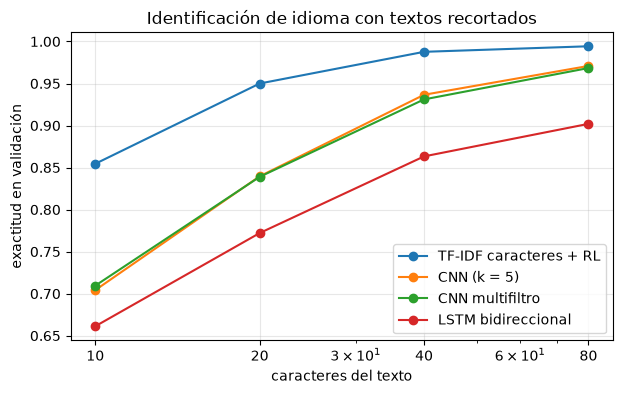

,TF-IDF caracteres + RL,CNN (k = 5),CNN multifiltro,LSTM bidireccional
10,0.854,0.704,0.710,0.661
20,0.950,0.840,0.839,0.772
40,0.988,0.937,0.931,0.863
80,0.994,0.971,0.968,0.902


In [12]:
def exactitud_recortada(n):
    textos = [t[:n] for t in X_val_txt]
    X = vec(np.array(textos)).numpy()
    return {
        "TF-IDF caracteres + RL": accuracy_score(y_val, base.predict(tfidf.transform(textos))),
        "CNN (k = 5)": accuracy_score(y_val, cnn.predict(X, batch_size=512, verbose=0).argmax(1)),
        "CNN multifiltro": accuracy_score(y_val, multi.predict(X, batch_size=512, verbose=0).argmax(1)),
        "LSTM bidireccional": accuracy_score(y_val, bilstm.predict(X, batch_size=512, verbose=0).argmax(1)),
    }


longitudes_prueba = [10, 20, 40, 80]
robustez = pd.DataFrame({n: exactitud_recortada(n) for n in longitudes_prueba}).T
robustez.plot(marker="o", figsize=(7, 4))
plt.xscale("log")
plt.xticks(longitudes_prueba, longitudes_prueba)
plt.xlabel("caracteres del texto")
plt.ylabel("exactitud en validación")
plt.title("Identificación de idioma con textos recortados")
plt.grid(alpha=0.3)
plt.show()
robustez.round(3)

In [13]:
# el más rápido entre los modelos a menos de 0,2 puntos del mejor en validación
candidatos = comparacion[comparacion["exactitud en validación"] >= comparacion["exactitud en validación"].max() - 0.002]
MEJOR = candidatos["inferencia en validación (s)"].idxmin()
modelos = {"CNN de caracteres (k = 5)": cnn, "CNN multifiltro (k = 2, 3, 4, 5)": multi, "LSTM bidireccional": bilstm}
if MEJOR == "TF-IDF caracteres + RL":
    pred_test = base.predict(tfidf.transform(X_test_txt))
else:
    pred_test = modelos[MEJOR].predict(X_test, batch_size=512, verbose=0).argmax(1)
print(f"Modelo elegido en validación: {MEJOR}")
print(f"Exactitud en PRUEBA: {accuracy_score(y_test, pred_test):.4f}")
por_idioma = pd.Series({c: (pred_test[y_test == i] == i).mean() for i, c in enumerate(CLASES)}, name="exactitud")
por_idioma.sort_values().round(3).to_frame().T

Modelo elegido en validación: TF-IDF caracteres + RL
Exactitud en PRUEBA: 0.9949


,ur,hi,pl,it,pt,nl,es,ar,sw,ru,de,bg,fr,en,ja,el,th,tr,vi,zh
exactitud,0.964,0.968,0.992,0.994,0.994,0.996,0.998,0.998,0.998,0.998,0.998,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


**Interpretación:**

- La LSTM bidireccional es la peor en todo: 91,6 % en validación tras 10 épocas, unas 8 veces más lenta por época que la CNN y 10 veces más lenta para predecir. Identificar el idioma no requiere dependencias largas: basta con detectar unos pocos N-gramas característicos, y para eso la recurrencia sobra.
- Con textos cortos todos los modelos empeoran, pero el orden se mantiene: con 10 caracteres, TF-IDF acierta el 85 %, las CNN el 70 % y la LSTM el 66 %; con 40 caracteres, TF-IDF ya llega al 98,8 %. Los modelos neuronales se entrenaron con textos completos y casi nunca vieron fragmentos tan cortos; entrenarlos también con recortes (aumento de datos) probablemente los haría más robustos.
- El modelo elegido en validación es la línea base TF-IDF (las CNN quedan casi 2 puntos por debajo), con 99,49 % en prueba. Los idiomas con menor exactitud son el urdu y el hindi (96–97 %), por los textos romanizados.
- **En producción** usaríamos el modelo de N-gramas de caracteres: es el más exacto y el más robusto con textos cortos, se entrena en medio minuto y no requiere GPU. Si la latencia fuera crítica, una CNN pequeña sería una alternativa razonable. La lección general: el modelo más complejo no siempre es el mejor, y siempre hay que compararlo con una línea base fuerte.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Chollet, F. (2021). *Deep Learning with Python* (2.ª ed.). Manning.
- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Kim, Y. (2014). Convolutional Neural Networks for Sentence Classification. *EMNLP*.
- Zhang, X., Zhao, J. & LeCun, Y. (2015). Character-level Convolutional Networks for Text Classification. *NeurIPS*.
- Jauhiainen, T., Lui, M., Zampieri, M., Baldwin, T. & Lindén, K. (2019). Automatic Language Identification in Texts: A Survey. *Journal of Artificial Intelligence Research*, 65.
- Conjunto de datos: [papluca/language-identification](https://huggingface.co/datasets/papluca/language-identification) (Hugging Face).